# Chapitre 12 - Cours 7 : vie privée, pistage et surveillance

Le cours précédent portait sur l'usage des données pour **décider** à propos des
personnes. Celui-ci remonte d'un cran : la **collecte** elle-même pose problème. Quelle
relation lie l'organisation qui collecte et les personnes dont elle collecte les
données ? Le notebook couvre la partie *Privacy and Tracking* (sous-sections *Surveillance*, *Consent and freedom of choice*, *Privacy and use of data*, *Data as assets and power*, *Remembering the Industrial Revolution*, *Legislation and self-regulation*),
qui clôt le livre.

Comme au cours précédent, toutes les données sont **synthétiques** : une population
fictive de 100 000 personnes (code postal, date de naissance, sexe, quelques
attributs), générée par `et.make_population`. Elle suffit à montrer pourquoi
« anonymiser » est si difficile.

**Plan.**

1. Du service rendu au pistage.
2. Surveillance : l'anonymat est une illusion.
3. Consentement et liberté de choix.
4. Vie privée et usage des données.
5. Les données, un actif toxique et une source de pouvoir.
6. Se souvenir de la révolution industrielle.
7. Législation et autorégulation.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import ethics as et
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Du service rendu au pistage (section *Privacy and Tracking*)

Quand un système ne stocke que ce que l'utilisateur y a saisi, pour qu'il le stocke et
le traite comme il l'a demandé, le système **rend un service** : l'utilisateur est le
client. Quand l'activité de l'utilisateur est enregistrée **en passant**, comme effet de
bord de ce qu'il fait, la relation se brouille : le service se met à poursuivre ses
propres intérêts, qui peuvent s'opposer à ceux de l'utilisateur.

Une part de pistage profite aux utilisateurs : savoir quels résultats de recherche sont
cliqués améliore le classement, les recommandations « ceux qui ont aimé X ont aussi aimé
Y » font découvrir des choses utiles, les tests A/B améliorent l'interface. Mais si le
service vit de la publicité, ses vrais clients sont les **annonceurs** : le pistage
devient plus fin, les analyses plus poussées, les données conservées plus longtemps,
pour construire un profil marketing détaillé de chacun. Le mot qui décrit cette
relation a des connotations plus sombres : **surveillance**.

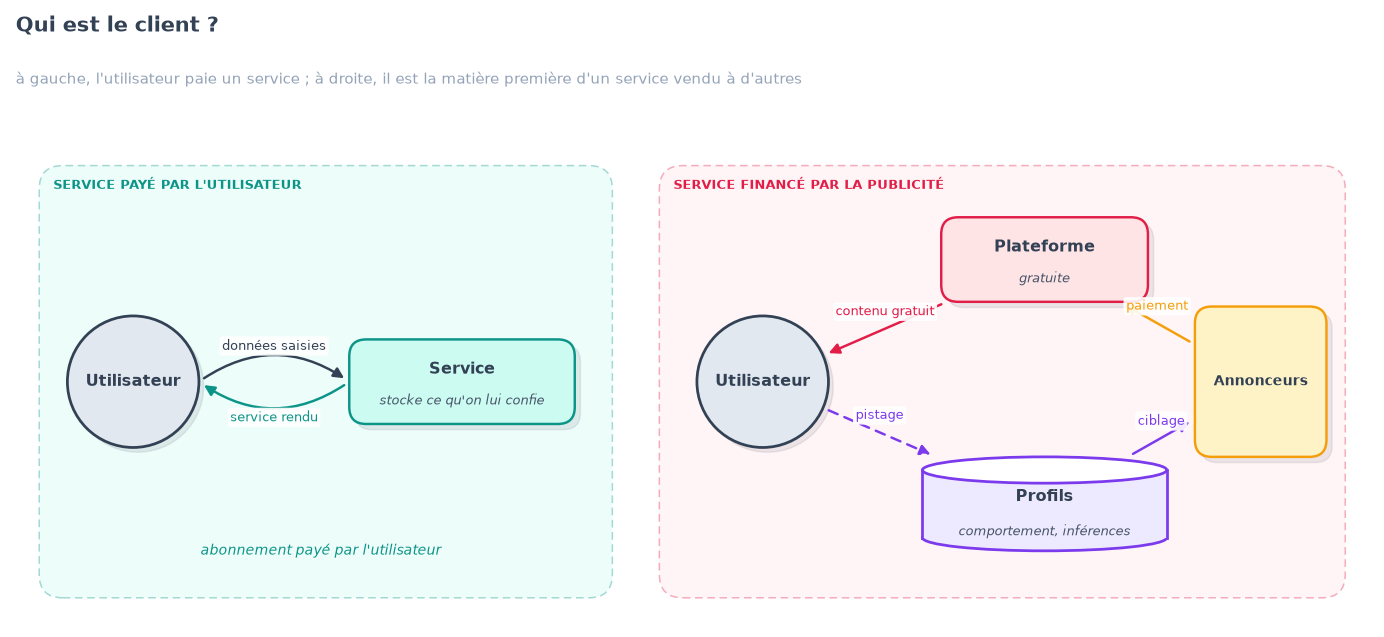

In [2]:
d = Diagram(14.5, 5.6, title="Qui est le client ?",
            subtitle="à gauche, l'utilisateur paie un service ; à droite, il est la matière première d'un service vendu à d'autres")
d.group(0.3, 0.3, 6.4, 4.9, "service payé par l'utilisateur", color=TEAL)
d.box("u1", 1.3, 2.6, "Utilisateur", kind="user", w=1.4, color=SLATE)
d.box("s1", 4.8, 2.6, "Service", sub="stocke ce qu'on lui confie", color=TEAL, w=2.4)
d.arrow("u1", "s1", "données saisies", rad=-0.35, label_offset=(0, 0.1))
d.arrow("s1", "u1", "service rendu", rad=-0.35, color=TEAL, label_offset=(0, -0.1))
d.note(3.3, 0.8, "abonnement payé par l'utilisateur", color=TEAL)
d.group(6.9, 0.3, 14.2, 4.9, "service financé par la publicité", color=ROSE)
d.box("u2", 8.0, 2.6, "Utilisateur", kind="user", w=1.4, color=SLATE)
d.box("s2", 11.0, 3.9, "Plateforme", sub="gratuite", color=ROSE, w=2.2)
d.box("p2", 11.0, 1.3, "Profils", sub="comportement, inférences", color=VIOLET, kind="db", w=2.6, h=1.0)
d.box("a2", 13.3, 2.6, "Annonceurs", color=AMBER, w=1.4, h=1.6, fontsize=9)
d.arrow("s2", "u2", "contenu gratuit", color=ROSE)
d.arrow("u2", "p2", "pistage", style="dashed", color=VIOLET)
d.arrow("p2", "a2", "ciblage", color=VIOLET)
d.arrow("a2", "s2", "paiement", color=AMBER)
d.show()

> **À retenir.** La question décisive est « qui paie ? ». Quand ce sont les annonceurs,
> l'utilisateur n'est plus le client mais la source des données vendues, et le pistage
> tend à dépasser ce qui sert l'utilisateur.